# Faster R-CNN Training Notebook

This notebook trains a Faster R-CNN object detection model using PyTorch on a custom dataset.

Based on: https://visionbrick.com/pipeline-for-training-custom-faster-rcnn-object-detection-models-with-pytorch/

## Establish an environment

In [14]:
try:
    import google.colab

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Running on Google Colab")
else:
    print("Running locally")

Running locally


In [15]:
!nvidia-smi

Sat Jan 31 11:18:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.95.05              Driver Version: 580.95.05      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4070        Off |   00000000:01:00.0  On |                  N/A |
|  0%   43C    P8             19W /  200W |    7250MiB /  12282MiB |     13%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Download data from Roboflow API (API_KEY required) or from local machine

In [16]:
import os
from pathlib import Path

USE_ROBOFLOW_API = True

DATASET_NAME = "package_sorting"

ROBOFLOW_PROJECTS = {
    "package_sorting": {
        "workspace": "lukmik-e4qay",
        "project": "mailers-and-boxes-v10",
        "version": 6,
    },
}
FORMAT = "coco"

if USE_ROBOFLOW_API:
    if IN_COLAB:
        %pip install roboflow
        from google.colab import userdata

        ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
        DATASET_LOCATION = f"datasets/{FORMAT}"
    else:
        from dotenv import load_dotenv

        load_dotenv()
        ROBOFLOW_API_KEY = os.getenv("ROBOFLOW_API_KEY")
        DATASET_LOCATION = f"../datasets/{FORMAT}"

    from roboflow import Roboflow

    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    proj_config = ROBOFLOW_PROJECTS[DATASET_NAME]
    project = rf.workspace(proj_config["workspace"]).project(
        proj_config["project"]
    )
    version = project.version(proj_config["version"])
    dataset = version.download(FORMAT, location=DATASET_LOCATION)
    DATASET_PATH = Path(dataset.location)
else:
    if IN_COLAB:
        DATASET_PATH = Path(f"datasets/{DATASET_NAME}/{FORMAT}")
    else:
        DATASET_PATH = Path(f"../datasets/{DATASET_NAME}/{FORMAT}")

print(f"Dataset path: {DATASET_PATH.resolve()}")
print(f"Dataset exists: {DATASET_PATH.exists()}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to ../datasets/package_sorting/coco in coco:: 100%|██████████| 572/572 [00:00<00:00, 15272.79it/s]

Dataset path: /home/lukmik/Desktop/university/masters2.1/wybrane_metody_uczenia_maszynowego/projekt/datasets/package_sorting/coco
Dataset exists: True


## Install Dependencies

In [ ]:
if IN_COLAB:
    %pip install pycocotools torchmetrics pandas

## Import Libraries and Check GPU

In [18]:
import matplotlib.pyplot as plt
import cv2
import os
import torch
import torchvision
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader
from pycocotools.coco import COCO
from torchvision.transforms import ToTensor
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


## Custom PyTorch Dataset Class for COCO Format

In [19]:
class CocoDetectionDataset(Dataset):
    """
    Custom PyTorch Dataset to load COCO-format annotations and images.
    """

    def __init__(self, image_dir, annotation_path, transforms=None):
        self.image_dir = image_dir
        self.coco = COCO(annotation_path)
        self.image_ids = list(self.coco.imgs.keys())
        self.transforms = transforms

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_info = self.coco.loadImgs(image_id)[0]
        image_path = os.path.join(self.image_dir, image_info["file_name"])
        image = Image.open(image_path).convert("RGB")

        annotation_ids = self.coco.getAnnIds(imgIds=image_id)
        annotations = self.coco.loadAnns(annotation_ids)

        boxes = []
        labels = []
        areas = []
        iscrowd = []

        for obj in annotations:
            xmin, ymin, width, height = obj["bbox"]
            xmax = xmin + width
            ymax = ymin + height

            if width <= 0 or height <= 0:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(obj["category_id"])
            areas.append(obj["area"])
            iscrowd.append(obj.get("iscrowd", 0))

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            areas = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            areas = torch.as_tensor(areas, dtype=torch.float32)
            iscrowd = torch.as_tensor(iscrowd, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([image_id]),
            "area": areas,
            "iscrowd": iscrowd,
        }

        if self.transforms:
            image = self.transforms(image)

        return image, target

## Create Train and Validation DataLoaders

In [20]:
def get_transform():
    return ToTensor()


def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = CocoDetectionDataset(
    image_dir=str(DATASET_PATH / "train"),
    annotation_path=str(DATASET_PATH / "train" / "_annotations.coco.json"),
    transforms=get_transform(),
)

val_dataset = CocoDetectionDataset(
    image_dir=str(DATASET_PATH / "valid"),
    annotation_path=str(DATASET_PATH / "valid" / "_annotations.coco.json"),
    transforms=get_transform(),
)

BATCH_SIZE = 2
NUM_WORKERS = 4 if not IN_COLAB else 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Number of classes: {len(train_dataset.coco.getCatIds())}")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Training samples: 513
Validation samples: 50
Number of classes: 3


## Visualize Sample Images from DataLoader

Categories: {0: 'packages', 1: 'box', 2: 'mailer'}


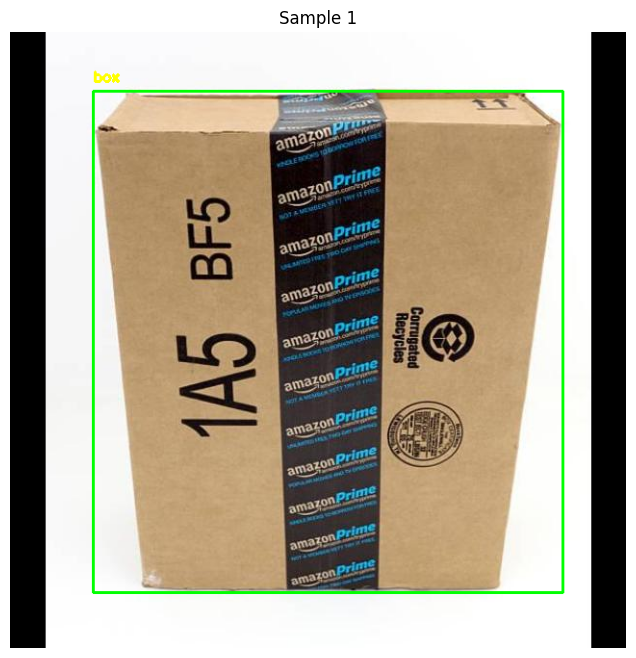

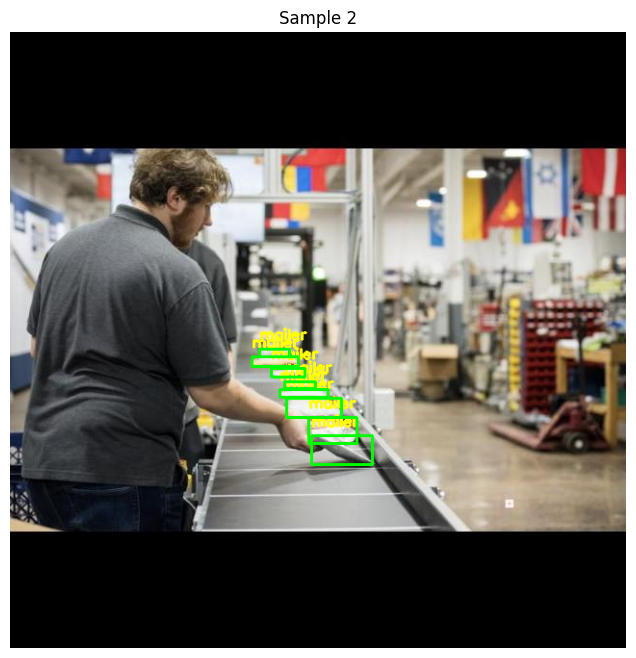

In [21]:
cat_ids = train_dataset.coco.getCatIds()
cats = train_dataset.coco.loadCats(cat_ids)
cat_id_to_name = {cat["id"]: cat["name"] for cat in cats}
print(f"Categories: {cat_id_to_name}")

images, targets = next(iter(train_loader))

for i in range(min(2, len(images))):
    image = images[i].permute(1, 2, 0).numpy()
    image = (image * 255).astype(np.uint8)
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

    boxes = targets[i]["boxes"]
    labels = targets[i]["labels"]

    for box, label in zip(boxes, labels):
        x1, y1, x2, y2 = map(int, box.tolist())
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        label_name = cat_id_to_name.get(label.item(), f"Class {label.item()}")
        cv2.putText(
            image,
            label_name,
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 255),
            2,
        )

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"Sample {i + 1}")
    plt.show()

## Setup Weights Directory

In [ ]:
from pathlib import Path
import os

# Setup shared weights directory
if IN_COLAB:
    WEIGHTS_DIR = Path("weights")
else:
    WEIGHTS_DIR = (Path.cwd().parent / "weights").resolve()
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

# Configure torchvision to use the shared weights directory
os.environ["TORCH_HOME"] = str(WEIGHTS_DIR)
print(f"Weights will be cached in: {WEIGHTS_DIR}")

## Load Pre-trained Faster R-CNN Model

In [22]:
def get_faster_rcnn_model(num_classes):
    """
    Load a pre-trained Faster R-CNN model and replace the classifier head.

    Args:
        num_classes: Number of classes (including background)

    Returns:
        Faster R-CNN model
    """
    model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_fpn(
        weights="DEFAULT"
    )
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model


num_classes = len(train_dataset.coco.getCatIds()) + 1
print(f"Number of classes (including background): {num_classes}")

model = get_faster_rcnn_model(num_classes)
model.to(device)

print(f"Model loaded and moved to {device}")

Number of classes (including background): 4
Model loaded and moved to cuda


In [ ]:
EPOCHS = 2

## Configure Training Parameters

In [23]:
NUM_EPOCHS = EPOCHS
LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
LR_STEP_SIZE = 5
LR_GAMMA = 0.5

params = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.SGD(
    params, lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=LR_STEP_SIZE, gamma=LR_GAMMA
)

print(
    f"Optimizer: SGD (lr={LEARNING_RATE}, momentum={MOMENTUM}, weight_decay={WEIGHT_DECAY})"
)
print(f"LR Scheduler: StepLR (step_size={LR_STEP_SIZE}, gamma={LR_GAMMA})")

Optimizer: SGD (lr=0.005, momentum=0.9, weight_decay=0.0005)
LR Scheduler: StepLR (step_size=5, gamma=0.5)


## Training Loop

In [ ]:
import gc
import time
from pathlib import Path

# Setup output directory
if IN_COLAB:
    OUTPUT_DIR = Path("training_outputs/faster_r_cnn")
else:
    OUTPUT_DIR = (
            Path.cwd().parent / "training_outputs" / "faster_r_cnn"
    ).resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUTPUT_DIR}")


def train_one_epoch(model, optimizer, data_loader, device, print_freq=10):
    """
    Train the model for one epoch.
    """
    model.train()

    total_loss = 0
    num_batches = 0

    for batch_idx, (images, targets) in enumerate(data_loader):
        images = list(img.to(device) for img in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()
        num_batches += 1

        if (batch_idx + 1) % print_freq == 0:
            print(
                f"  Batch [{batch_idx + 1}/{len(data_loader)}] "
                f"Loss: {losses.item():.4f} "
                f"(cls: {loss_dict['loss_classifier'].item():.4f}, "
                f"box: {loss_dict['loss_box_reg'].item():.4f}, "
                f"obj: {loss_dict['loss_objectness'].item():.4f}, "
                f"rpn: {loss_dict['loss_rpn_box_reg'].item():.4f})"
            )

    avg_loss = total_loss / num_batches
    return avg_loss


@torch.no_grad()
def evaluate(model, data_loader, device):
    """
    Evaluate the model on validation set.
    Returns average loss on validation set.
    """
    model.train()

    total_loss = 0
    num_batches = 0

    for images, targets in data_loader:
        images = list(img.to(device) for img in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        total_loss += losses.item()
        num_batches += 1

    avg_loss = total_loss / num_batches if num_batches > 0 else 0
    return avg_loss


@torch.no_grad()
def evaluate_coco_metrics(model, data_loader, device):
    """
    Evaluate model using COCO metrics via torchmetrics.
    Returns dict with mAP_50, mAP_50_95, precision, recall.
    """
    from torchmetrics.detection.mean_ap import MeanAveragePrecision

    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    metric.to(device)

    model.eval()

    predictions = []
    targets = []

    for images, target_batch in data_loader:
        images = list(img.to(device) for img in images)

        outputs = model(images)

        for target, output in zip(target_batch, outputs):
            # Convert predictions to torchmetrics format
            pred_boxes = output["boxes"].cpu()
            pred_scores = output["scores"].cpu()
            pred_labels = output["labels"].cpu()

            # Filter low confidence and background (class 0)
            mask = (pred_scores > 0.05) & (pred_labels > 0)

            predictions.append(
                {
                    "boxes": pred_boxes[mask],
                    "scores": pred_scores[mask],
                    "labels": pred_labels[mask],
                }
            )

            # Convert targets to torchmetrics format
            tgt_boxes = target["boxes"].cpu()
            tgt_labels = target["labels"].cpu()

            targets.append(
                {
                    "boxes": tgt_boxes,
                    "labels": tgt_labels,
                }
            )

    if len(predictions) == 0 or len(targets) == 0:
        return {
            "mAP_50": 0.0,
            "mAP_50_95": 0.0,
            "precision": 0.0,
            "recall": 0.0,
        }

    # Compute metrics
    metric.update(predictions, targets)
    result = metric.compute()

    return {
        "mAP_50": result["map_50"].item(),
        "mAP_50_95": result["map"].item(),
        "precision": result["map_50"].item(),  # Use mAP@50 as proxy
        "recall": result["mar_100"].item(),
    }


# Results history for CSV export
results_history = []

best_val_loss = float("inf")
training_start_time = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start_time = time.time()
    torch.cuda.empty_cache()
    gc.collect()

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print("-" * 40)

    train_loss = train_one_epoch(
        model, optimizer, train_loader, device, print_freq=25
    )

    lr_scheduler.step()

    val_loss = evaluate(model, val_loader, device)

    epoch_time = time.time() - epoch_start_time
    current_lr = optimizer.param_groups[0]["lr"]

    # Compute COCO metrics every epoch for comparison with DETR/YOLO
    coco_metrics = evaluate_coco_metrics(model, val_loader, device)

    # Record results for this epoch
    results_history.append(
        {
            "epoch": epoch + 1,
            "train/loss": train_loss,
            "val/loss": val_loss,
            "lr": current_lr,
            "epoch_time": epoch_time,
            "mAP_50": coco_metrics["mAP_50"],
            "mAP_50_95": coco_metrics["mAP_50_95"],
            "precision": coco_metrics["precision"],
            "recall": coco_metrics["recall"],
        }
    )

    print(
        f"  Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"LR: {current_lr:.6f} | Time: {epoch_time:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_path = OUTPUT_DIR / f"faster_rcnn_best_{DATASET_NAME}.pth"
        torch.save(model.state_dict(), best_model_path)
        print(
            f"  -> Saved best model to {best_model_path} (val_loss: {val_loss:.4f})"
        )

    if (epoch + 1) % 5 == 0:
        checkpoint_path = (
                OUTPUT_DIR / f"faster_rcnn_epoch_{epoch + 1}_{DATASET_NAME}.pth"
        )
        torch.save(
            model.state_dict(),
            checkpoint_path,
        )
        print(
            f"  -> Saved checkpoint to {checkpoint_path} at epoch {epoch + 1}"
        )

total_training_time = time.time() - training_start_time
print("\n" + "=" * 60)
print(f"Training complete! Total time: {total_training_time / 60:.2f} minutes")
print(f"Best validation loss: {best_val_loss:.4f}")
# Save results to CSV
import pandas as pd

results_df = pd.DataFrame(results_history)
results_csv_path = OUTPUT_DIR / f"faster_rcnn_results_{DATASET_NAME}.csv"
results_df.to_csv(results_csv_path, index=False)
print(f"Results saved to: {results_csv_path}")

## Training Visualization

Generate charts to compare with other models.

In [ ]:
import pandas as pd

results_df = pd.read_csv(OUTPUT_DIR / "faster_rcnn_results_package_sorting.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(results_df['epoch'], results_df['train/loss'], label='Train Loss',
             marker='o')
axes[0].plot(results_df['epoch'], results_df['val/loss'], label='Val Loss', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training vs Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(results_df['epoch'], results_df['mAP_50'], label='mAP@50', marker='o',
             color='blue')
axes[1].plot(results_df['epoch'], results_df['mAP_50_95'], label='mAP@50-95',
             marker='s', color='green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mAP')
axes[1].set_title('Mean Average Precision')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(results_df['epoch'], results_df['precision'], label='Precision',
             marker='o', color='orange')
axes[2].plot(results_df['epoch'], results_df['recall'], label='Recall', marker='s',
             color='red')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Score')
axes[2].set_title('Precision vs Recall')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "faster_rcnn_training_curves.png", dpi=150,
            bbox_inches='tight')
plt.show()

print(f"Charts saved to: {OUTPUT_DIR / 'faster_rcnn_training_curves.png'}")

## Inference on Test Images

Loaded best model for inference

Processing: 052116amazon33cs_jpg.rf.b3eb8ff8cf5ea8b6866d6d29f8b931d9.jpg


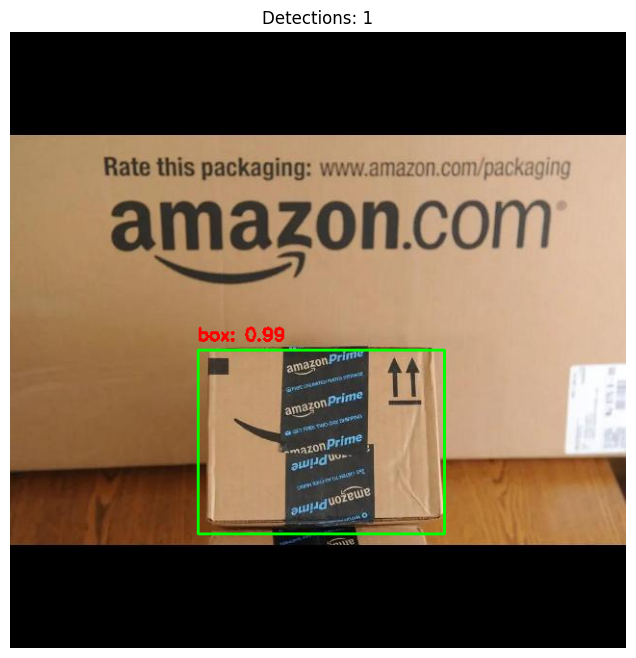


Processing: automated-sorting-conveyor-system-pushing-box_webp.rf.e4b07cacc01b5c1965020138db6e7513.jpg


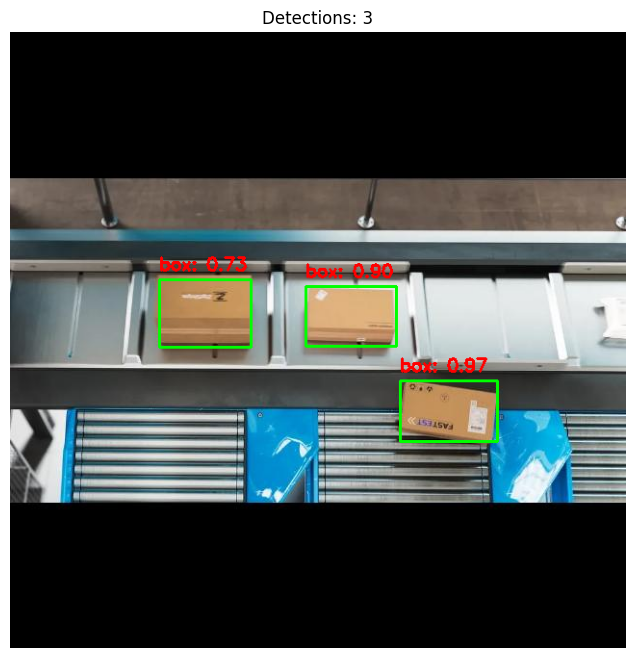


Processing: 20220422_005440729_iOS_jpg.rf.5bfcdbab0e999552818a329679c458d4.jpg


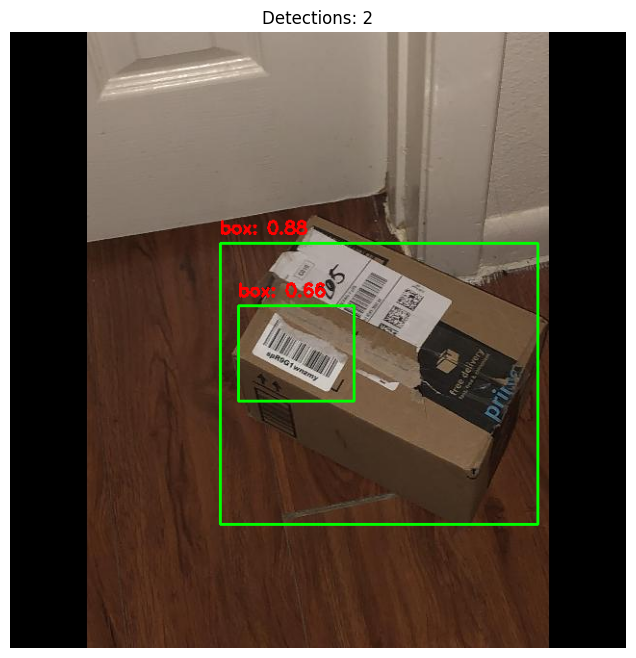


Processing: csm_Small_parcels_distribution_Conveying_e7ba7bb175_jpg.rf.d5c63ad9809073f94fe9c8ff2be82316.jpg


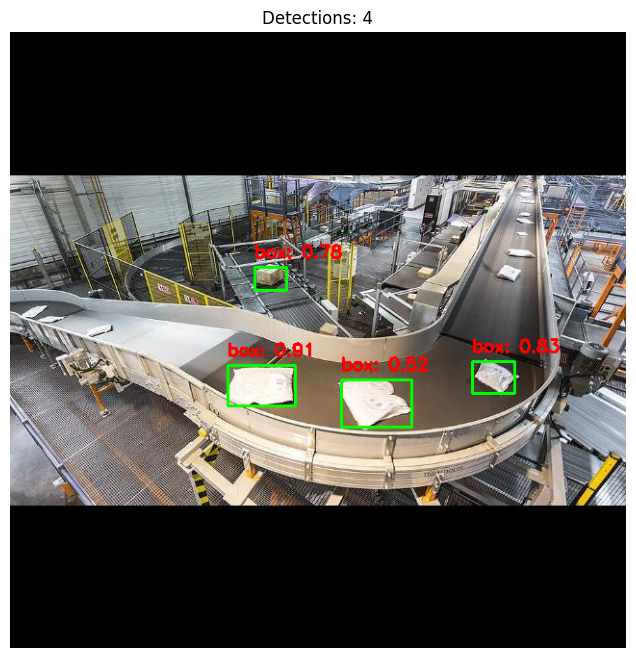


Processing: 104_jpg.rf.70bbca6321ca4baaa73c40b6a32b604f.jpg


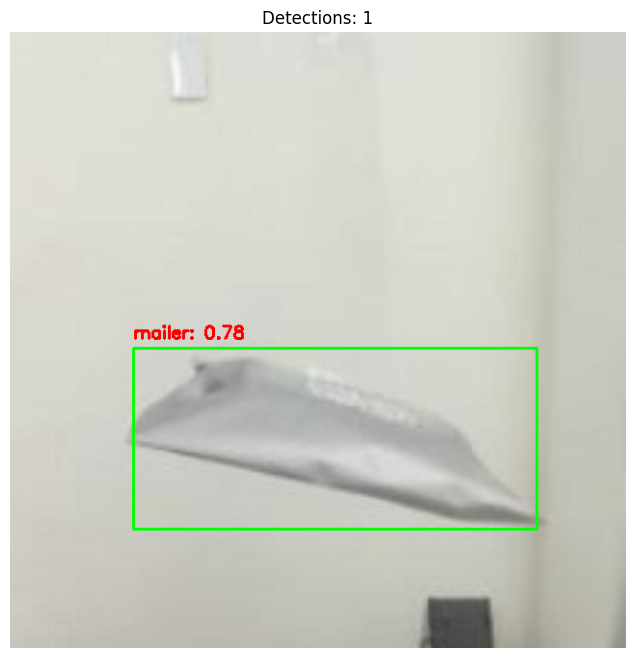

In [25]:
def run_inference(model, image_path, device, threshold=0.5):
    """
    Run inference on a single image.

    Args:
        model: Trained Faster R-CNN model
        image_path: Path to image
        device: Device to run inference on
        threshold: Confidence threshold for detections

    Returns:
        predictions dict with boxes, labels, scores
    """
    model.eval()

    image = Image.open(image_path).convert("RGB")
    image_tensor = ToTensor()(image).unsqueeze(0).to(device)

    with torch.no_grad():
        predictions = model(image_tensor)

    pred = predictions[0]
    mask = pred["scores"] > threshold

    return {
        "boxes": pred["boxes"][mask].cpu(),
        "labels": pred["labels"][mask].cpu(),
        "scores": pred["scores"][mask].cpu(),
    }


def visualize_predictions(image_path, predictions, cat_id_to_name):
    """
    Visualize predictions on an image.
    """
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    boxes = predictions["boxes"]
    labels = predictions["labels"]
    scores = predictions["scores"]

    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = map(int, box.tolist())
        label_name = cat_id_to_name.get(label.item(), f"Class {label.item()}")
        text = f"{label_name}: {score.item():.2f}"

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            image,
            text,
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2,
        )

    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Detections: {len(boxes)}")
    plt.show()


best_model_path = OUTPUT_DIR / f"faster_rcnn_best_{DATASET_NAME}.pth"
model.load_state_dict(torch.load(best_model_path))
model.eval()
print("Loaded best model for inference")

val_images_dir = DATASET_PATH / "valid"
image_files = list(val_images_dir.glob("*.jpg"))[:5]  # First 5 images

for img_path in image_files:
    print(f"\nProcessing: {img_path.name}")
    predictions = run_inference(model, img_path, device, threshold=0.5)
    visualize_predictions(img_path, predictions, cat_id_to_name)

## Export Model

Save the final trained model to the models directory.

In [26]:
import json

# Save final model and config to OUTPUT_DIR
final_model_path = OUTPUT_DIR / f"faster_rcnn_{DATASET_NAME}_final.pth"
torch.save(model.state_dict(), final_model_path)
print(f"Final model saved to: {final_model_path}")

best_model_path = OUTPUT_DIR / f"faster_rcnn_best_{DATASET_NAME}.pth"
print(f"Best model saved to: {best_model_path}")

config = {
    "dataset": DATASET_NAME,
    "num_classes": num_classes,
    "epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "momentum": MOMENTUM,
    "weight_decay": WEIGHT_DECAY,
    "best_val_loss": best_val_loss,
    "categories": cat_id_to_name,
}

config_path = OUTPUT_DIR / "training_config.json"
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)
print(f"Training config saved to: {config_path}")

Final model saved to: ../models/faster_rcnn/package_sorting/faster_rcnn_package_sorting_final.pth
Best model saved to: ../models/faster_rcnn/package_sorting/faster_rcnn_package_sorting_best.pth
Training config saved to: ../models/faster_rcnn/package_sorting/training_config.json
